# Atlas-DeePC: ranks 59, 62 and 64 over 1,000 seeds

This report reads the completed 3,000-rollout experiment. It never runs simulations.
Until all results exist, the first code cell deliberately refuses to report a final success rate.

All three ranks use **λg = 0.05 and Clarabel**, the same 1,000 testing seeds **311–1310**, and 320 control steps per rollout. The copied offline data and 48-chart atlas are hash-identical to the original 100-seed Clarabel study. Chart memberships, centers, and routing graph are fixed; the bases are nested prefixes with rank-dependent coefficient bounds computed by the original rule. No data collection or chart fitting occurs during evaluation.

Success requires **both** the last-30 and last-100 windows to have mean target error below 10 mm and maximum below 20 mm. Unsolved QPs retain the original zero-action behavior and count toward the outcome. Success intervals are 95% Wilson intervals; paired outcome counts compare identical seeds. Rank selection used the earlier 100-seed study, so this report evaluates the selected ranks on a separate seed panel.

Trials run serially with one numerical thread and rank order rotated within each seed. All 320 per-step times are saved; summary timing excludes the first five steps of each rollout (315,000 timed steps per rank). QP timing includes construction and solving. Offline cache setup, per-rollout goal setup, and rollout wall time are separate. These are wall-clock measurements on a shared computer.


In [1]:
RUN_EXPERIMENTS = False
from pathlib import Path
from collections import Counter
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/selected_rank_1000_clarabel.py").exists())
RESULT = ROOT / "experiments/routed_deepc_iid/selected_ranks_1000_clarabel_v1"
FIGURES = RESULT / "figures"
FIGURES.mkdir(exist_ok=True)
summary = json.loads((RESULT / "summary.json").read_text())
assert summary["complete"] and summary["rollouts"] == 3000
assert summary["ranks"] == [59, 62, 64] and summary["seeds"] == list(range(311, 1311))
sys.path.insert(0, str(RESULT / "frozen_protocol/src"))
import selected_rank_1000_experiment as experiment
assert experiment.prepare() == summary["signature"]
invariance = json.loads((RESULT / "invariance_latest.json").read_text())
assert invariance["passed"] and invariance["through_seed"] == 1310
reports = {rank: json.loads((RESULT / f"rank{rank:03d}/summary.json").read_text()) for rank in summary["ranks"]}
rows, times = {}, {}
for rank, report in reports.items():
    checked = [experiment.e.load_checkpoint(experiment.e.checkpoint_path(rank, seed), rank, seed) for seed in summary["seeds"]]
    assert checked == report["results"]
    assert report["timing"]["timed_steps"] == 315000
    rows[rank] = pd.DataFrame(checked).set_index("seed").sort_index()
    assert len(rows[rank]) == 1000 and (rows[rank]["steps"] == 320).all()
    assert int((rows[rank].success_30 & rows[rank].success_100).sum()) == report["successes"]
    times[rank] = pd.DataFrame(report["timing"]["modules"]).set_index("module")
for rank in (62, 64):
    np.testing.assert_array_equal(rows[rank].exact_target_xy.tolist(), rows[59].exact_target_xy.tolist())
plt.rcParams.update({"figure.dpi": 125, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = ["#2563eb", "#0d9488", "#d97706"]
def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name + ".png"), bbox_inches="tight")
    plt.show()
print("Verified 3,000 full rollouts, paired targets, source/data hashes, and final offline invariance audit.")


Verified 3,000 full rollouts, paired targets, source/data hashes, and final offline invariance audit.


## Success and tracking error

,successes,success_rate_pct,95% interval,median_tail100_mm,p90_tail100_mm,unsolved_qps
rank,,,,,,
59,965,96.5,95.17–97.47%,2.016,4.434,0
62,959,95.9,94.49–96.96%,1.967,4.316,0
64,952,95.2,93.69–96.36%,2.016,4.322,0


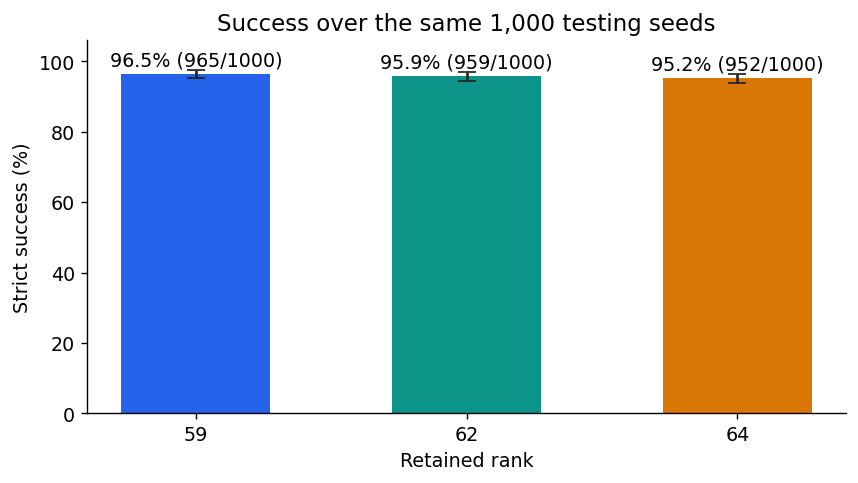

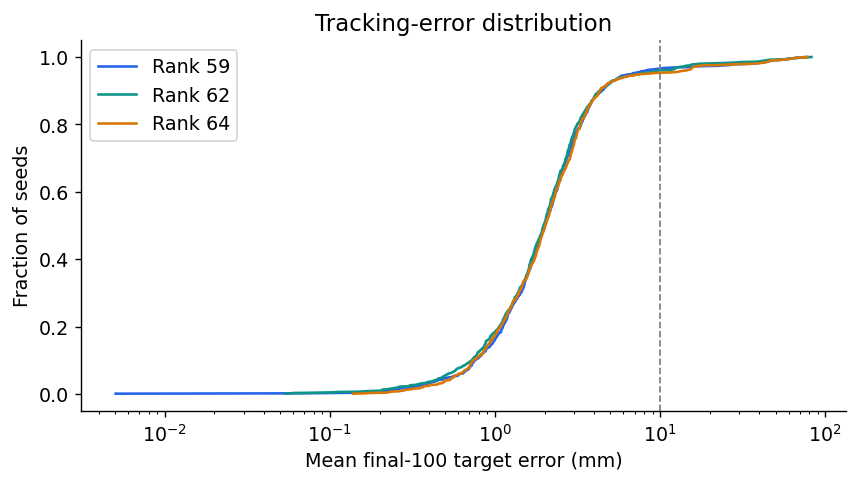

In [2]:
def wilson(k, n=1000, z=1.959963984540054):
    p = k/n
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    return 100*np.array([center-half, center+half])
table = pd.DataFrame(summary["completed"]).set_index("rank")
table["success_rate_pct"] = table.successes/10
table["95% interval"] = ["%.2f–%.2f%%" % tuple(wilson(k)) for k in table.successes]
display(table[["successes", "success_rate_pct", "95% interval", "median_tail100_mm", "p90_tail100_mm", "unsolved_qps"]].round(3))
fig, ax = plt.subplots(figsize=(7, 4))
rates = table.success_rate_pct.to_numpy()
intervals = np.array([wilson(k) for k in table.successes])
ax.bar([str(r) for r in reports], rates, color=colors, width=.55)
ax.errorbar(range(3), rates, yerr=np.vstack([rates-intervals[:,0], intervals[:,1]-rates]), fmt="none", color="#222222", capsize=5)
for i, (rate, count) in enumerate(zip(rates, table.successes)):
    ax.text(i, min(102, intervals[i,1]+1.3), f"{rate:.1f}% ({count}/1000)", ha="center")
ax.set(xlabel="Retained rank", ylabel="Strict success (%)", ylim=(0, 106), title="Success over the same 1,000 testing seeds")
save("success")

fig, ax = plt.subplots(figsize=(7, 4))
for color, (rank, frame) in zip(colors, rows.items()):
    ax.plot(np.sort(1000*frame.mean_last_100), np.arange(1, 1001)/1000, label=f"Rank {rank}", color=color)
ax.axvline(10, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Mean final-100 target error (mm)", ylabel="Fraction of seeds", xscale="log", title="Tracking-error distribution")
ax.legend()
save("tracking_error")


## Paired outcomes and solver statuses

In [3]:
paired = []
for a, b in ((59,62), (59,64), (62,64)):
    sa = rows[a].success_30 & rows[a].success_100
    sb = rows[b].success_30 & rows[b].success_100
    paired.append({"rank A": a, "rank B": b, "both succeed": int((sa & sb).sum()),
                   "A only": int((sa & ~sb).sum()), "B only": int((~sa & sb).sum()),
                   "both fail": int((~sa & ~sb).sum())})
display(pd.DataFrame(paired))
status_counts = {rank: dict(sum((Counter(x) for x in frame.statuses), Counter())) for rank, frame in rows.items()}
for rank, counts in status_counts.items():
    assert sum(counts.values()) == 320000
    assert counts == summary["statuses_by_rank"][str(rank)]
display(pd.DataFrame(status_counts).fillna(0).astype(int).rename_axis("Solver status"))


,rank A,rank B,both succeed,A only,B only,both fail
0,59,62,947,18,12,23
1,59,64,943,22,9,26
2,62,64,933,26,19,22


,59,62,64
Solver status,,,
optimal,320000,320000,320000


## Computation time

mean_ms  median_ms  p95_ms  p99_ms
Rank Module                                                          
59   Chart localization              0.051      0.049   0.066   0.081
     Terminal-reference selection    0.012      0.011   0.016   0.019
     Graph routing                   0.005      0.005   0.007   0.009
     Linear subspace retrieval       0.001      0.001   0.001   0.001
     QP construction and solve      30.589     29.388  33.880  59.170
     Other control-loop work         0.025      0.024   0.032   0.046
     Total online control           30.683     29.481  33.987  59.265
62   Chart localization              0.051      0.049   0.067   0.082
     Terminal-reference selection    0.012      0.011   0.016   0.019
     Graph routing                   0.005      0.005   0.007   0.009
     Linear subspace retrieval       0.001      0.001   0.001   0.001
     QP construction and solve      31.360     30.108  34.973  59.984
     Other control-loop work         0.025      0.024   0.032   0.046
     Total online control           31.454     30.202  35.082  60.086
64   Chart localization              0.052      0.049   0.067   0.082
     Terminal-reference selection    0.012      0.012   0.016   0.019
     Graph routing                   0.005      0.005   0.007   0.010
     Linear subspace retrieval       0.001      0.001   0.001   0.001
     QP construction and solve      32.206     30.885  36.585  60.793
     Other control-loop work         0.026      0.024   0.033   0.046
     Total online control           32.301     30.980  36.694  60.889

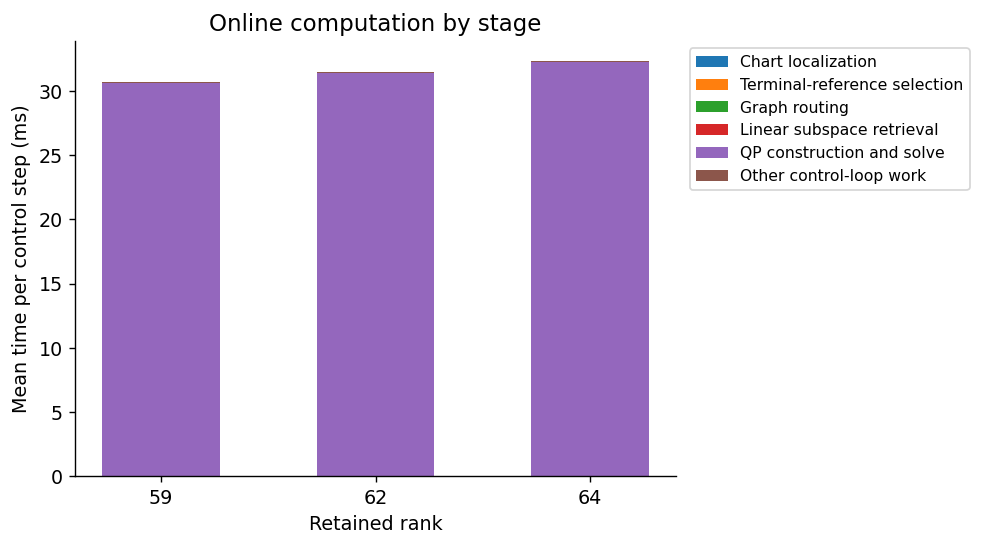

One-time goal setup per rollout (ms)


,mean,median,p95
Rank,,,
59,4.745,4.648,5.122
62,4.741,4.650,5.168
64,4.727,4.653,5.146


Offline matrix/route setup per process session (seconds)


,utc,matrix_and_route_setup_seconds_by_rank,total_load_and_setup_seconds
0,2026-09-16T02:58:12.153982+00:00,"{'59': 0.14826662512496114, '62': 0.1448991249...",0.528752
1,2026-09-16T02:58:29.037781+00:00,"{'59': 0.12270616600289941, '62': 0.1188698338...",0.443974


End-to-end rollout wall time (seconds; includes trace writing and checkpoint validation)


,count,mean,median,max
rank,,,,
59,1000,9.889,9.810,12.892
62,1000,10.137,10.069,12.163
64,1000,10.411,10.344,12.531


1919

In [4]:
timing_table = pd.concat(times, names=["Rank", "Module"])
display(timing_table[["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
stage_names = times[59].index.drop("Total online control")
bottom = np.zeros(3)
for module in stage_names:
    values = np.array([times[r].loc[module, "mean_ms"] for r in reports])
    ax.bar([str(r) for r in reports], values, bottom=bottom, label=module, width=.55)
    bottom += values
ax.set(xlabel="Retained rank", ylabel="Mean time per control step (ms)", title="Online computation by stage")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save("computation_time")
setup = pd.DataFrame({r: v["timing"]["one_time_goal_setup_ms"] for r, v in reports.items()}).T
setup.index.name = "Rank"
print("One-time goal setup per rollout (ms)")
display(setup.round(3))
print("Offline matrix/route setup per process session (seconds)")
display(pd.DataFrame([json.loads(p.read_text()) for p in sorted(RESULT.glob("setup_*.json"))]))
wall = [json.loads(line) for line in (RESULT / "rollout_wall_times.jsonl").read_text().splitlines()]
wall = pd.DataFrame([x for x in wall if not x["reused_checkpoint"]])
print("End-to-end rollout wall time (seconds; includes trace writing and checkpoint validation)")
display(wall.groupby("rank").seconds.agg(["count", "mean", "median", "max"]).round(3))
report = {"complete": True, "rollouts": 3000, "ranks": summary["completed"], "paired_outcomes": paired,
          "statuses_by_rank": status_counts, "timing_note": summary["timing_note"],
          "verified_offline_invariance": True, "figures": [str(p) for p in sorted(FIGURES.glob("*.png"))]}
(RESULT / "notebook_report.json").write_text(json.dumps(report, indent=2))
